# EDA: the users table

Who the users are, how complete their profiles are, and how much each of them contributes.

Inputs: `data/clean/users.parquet` and `data/eda/user_stats.parquet` (per-user aggregates
from `python -m cleaning.03_eda.aggregates`). Both are local files: nothing here prints a
username.

Usernames were collected in two ways: by polling MAL's recently-online page during the crawl
(July to October 2026), and from two older username lists, from 2022 and 2025. The users are
therefore a mix of accounts active during the crawl and accounts that stopped long before it
(`time.ipynb`, section 2).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parents[1]))

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from cleaning import config, plotting
from cleaning.plotting import BLUE, MUTED, ORANGE

plotting.use_style()
pl.Config.set_tbl_rows(30)
pl.Config.set_fmt_str_lengths(60)

users = pl.read_parquet(config.CLEAN_USERS).drop("username").join(
    pl.read_parquet(config.USER_STATS), on="user_id", how="left")
users = users.with_columns(n_watched=pl.col("n_completed") + pl.col("n_watching"))
print(f"{users.height:,} users, {users['n_ratings'].sum():,} rating rows")

1,907,258 users, 548,928,922 rating rows


## 1. Profile coverage

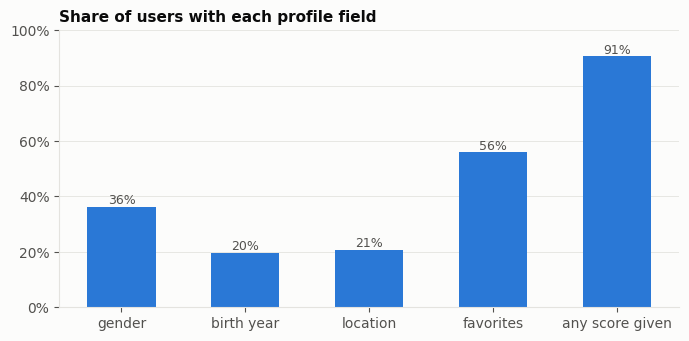

all users: {'gender': '36.3%', 'birth year': '19.8%', 'location': '20.7%', 'favorites': '55.8%', 'any score given': '90.5%'}


In [2]:
fields = {"gender": pl.col("gender").is_not_null(), "birth year": pl.col("birth_year").is_not_null(),
          "location": pl.col("location").is_not_null(), "favorites": pl.col("favorites").is_not_null(),
          "any score given": pl.col("n_scored") > 0}
overall = users.select([e.mean().alias(k) for k, e in fields.items()]).row(0, named=True)
fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.bar(list(fields), [overall[k] for k in fields], color=BLUE, width=0.55)
ax.bar_label(bars, labels=[f"{overall[k]:.0%}" for k in fields], color=MUTED, fontsize=9)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_ylim(0, 1)
ax.grid(axis="x", visible=False)
ax.set_title("Share of users with each profile field")
plt.show()
print("all users:", {k: f"{v:.1%}" for k, v in overall.items()})

Profile fields are sparse: 36% of users give a gender, 20% a birth year, 21% a location, and
56% list favorites. A model that uses profile features has to treat "missing" as the normal
case.

## 2. Gender, age and location

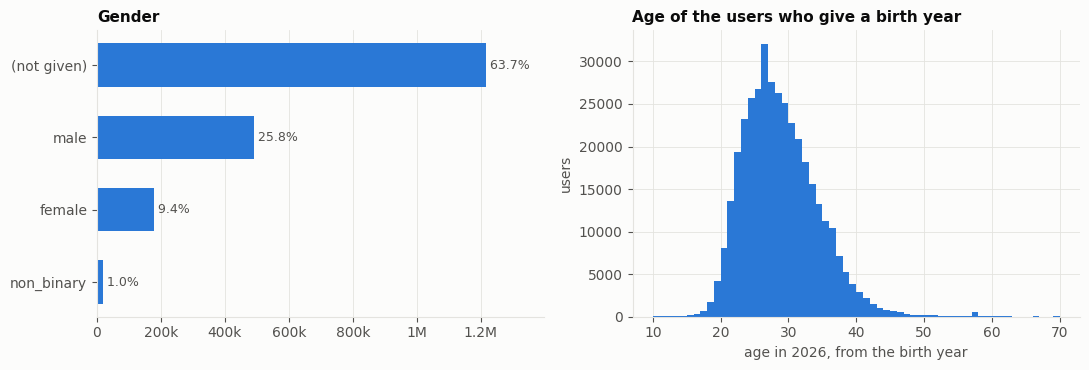

median age 28, middle 80% between 22 and 36
among users who state it: {'male': '71.2%', 'female': '26.0%', 'non_binary': '2.8%'}


location: 394,233 users, 103,982 distinct strings; top 15 hold 16.9%
shape: (15, 2)
┌───────────────┬───────┐
│ location      ┆ count │
│ ---           ┆ ---   │
│ str           ┆ u32   │
╞═══════════════╪═══════╡
│ germany       ┆ 7330  │
│ brazil        ┆ 6822  │
│ poland        ┆ 6352  │
│ canada        ┆ 5766  │
│ france        ┆ 5494  │
│ brasil        ┆ 4752  │
│ india         ┆ 4636  │
│ portugal      ┆ 3724  │
│ california    ┆ 3651  │
│ italy         ┆ 3511  │
│ australia     ┆ 3120  │
│ sweden        ┆ 3080  │
│ indonesia     ┆ 2784  │
│ united states ┆ 2781  │
│ finland       ┆ 2745  │
└───────────────┴───────┘


In [3]:
g = users["gender"].fill_null("(not given)").value_counts(sort=True)
age = users.filter(pl.col("birth_year").is_not_null()).select((2026 - pl.col("birth_year")).alias("age"))["age"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
bars = axes[0].barh(g["gender"].to_list(), g["count"].to_list(), color=BLUE, height=0.6)
axes[0].bar_label(bars, labels=[f" {v / users.height:.1%}" for v in g["count"]], color=MUTED, fontsize=9)
axes[0].invert_yaxis(); axes[0].set_xlim(0, g["count"].max() * 1.15); axes[0].grid(axis="y", visible=False)
plotting.thousands(axes[0], "x")
axes[0].set_title("Gender")
axes[1].hist(age, bins=np.arange(10, 71), color=BLUE)
axes[1].set_xlabel("age in 2026, from the birth year"); axes[1].set_ylabel("users")
axes[1].set_title("Age of the users who give a birth year")
plt.tight_layout()
plt.show()
print(f"median age {age.median():.0f}, middle 80% between {age.quantile(0.1):.0f} and {age.quantile(0.9):.0f}")
print("among users who state it:", {r[0]: f"{r[1] / users['gender'].is_not_null().sum():.1%}"
                                    for r in users["gender"].drop_nulls().value_counts(sort=True).rows()})
loc = users["location"].drop_nulls()
top = loc.str.to_lowercase().value_counts(sort=True).head(15)
print(f"location: {loc.len():,} users, {loc.n_unique():,} distinct strings; top 15 hold {top['count'].sum() / loc.len():.1%}")
print(top)

Among users who state a gender, 71% are male, 26% female and 3% non-binary. Ages concentrate
between 22 and 36 (median 28) among the fifth who give a year. Location is free text: 104k
distinct strings for 394k users, mixing countries, states and cities in several languages
(`brazil` and `brasil` are separate entries), so it needs normalising to a country before it
can be a feature.

## 3. Account age

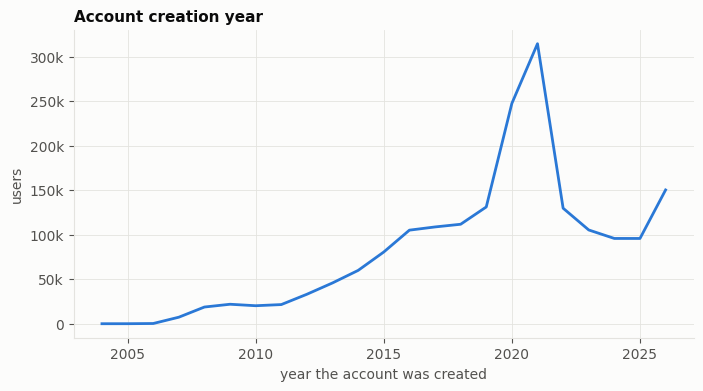

shape: (1, 3)
┌──────────────────┬──────────────────────┬────────────────┐
│ median join year ┆ joined 2025 or later ┆ joined in 2026 │
│ ---              ┆ ---                  ┆ ---            │
│ f64              ┆ f64                  ┆ u32            │
╞══════════════════╪══════════════════════╪════════════════╡
│ 2020.0           ┆ 0.129154             ┆ 150413         │
└──────────────────┴──────────────────────┴────────────────┘


In [4]:
joined = users.filter(pl.col("joined").is_not_null()).with_columns(year=pl.col("joined").dt.year())
by = joined.group_by("year").len().sort("year")
fig, ax = plt.subplots()
ax.plot(by["year"], by["len"], color=BLUE)
ax.set_xlabel("year the account was created"); ax.set_ylabel("users")
ax.set_title("Account creation year")
plotting.thousands(ax)
plt.show()
print(joined.select(pl.col("year").median().alias("median join year"),
                    (pl.col("year") >= 2025).mean().alias("joined 2025 or later"),
                    (pl.col("year") == 2026).sum().alias("joined in 2026")))

Account creation peaks in 2020-2021. 13% of accounts were created in 2025 or later, 150k of
them in 2026 alone, more than in all of 2025 although the crawl ended in October. These users
have short histories.

## 4. How much each user contributes

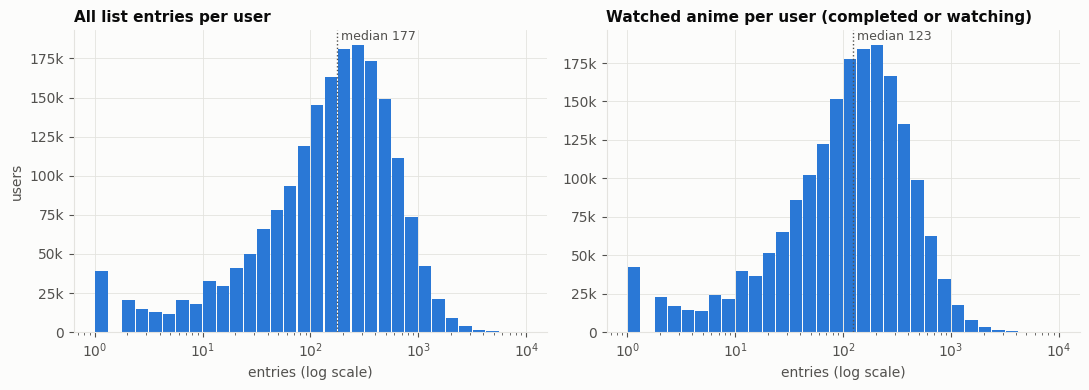

shape: (6, 7)
┌──────────┬───────────┬───────────┬─────────────┬─────────────────┬───────────┬──────────┐
│ quantile ┆ n_ratings ┆ n_watched ┆ n_completed ┆ n_plan_to_watch ┆ n_dropped ┆ n_scored │
│ ---      ┆ ---       ┆ ---       ┆ ---         ┆ ---             ┆ ---       ┆ ---      │
│ str      ┆ i64       ┆ i64       ┆ i64         ┆ i64             ┆ i64       ┆ i64      │
╞══════════╪═══════════╪═══════════╪═════════════╪═════════════════╪═══════════╪══════════╡
│ 10%      ┆ 16        ┆ 11        ┆ 7           ┆ 0               ┆ 0         ┆ 1        │
│ 25%      ┆ 64        ┆ 46        ┆ 39          ┆ 3               ┆ 0         ┆ 15       │
│ 50%      ┆ 177       ┆ 123       ┆ 112         ┆ 21              ┆ 2         ┆ 81       │
│ 75%      ┆ 378       ┆ 259       ┆ 240         ┆ 74              ┆ 9         ┆ 202      │
│ 90%      ┆ 672       ┆ 463       ┆ 434         ┆ 181             ┆ 26        ┆ 387      │
│ 99%      ┆ 1681      ┆ 1187      ┆ 1128        ┆ 688            

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
bins = np.logspace(0, 4, 33)
for ax, column, title in ((axes[0], "n_ratings", "All list entries per user"),
                          (axes[1], "n_watched", "Watched anime per user (completed or watching)")):
    v = users[column].to_numpy()
    ax.hist(v[v > 0], bins=bins, color=BLUE, rwidth=0.92)
    ax.set_xscale("log")
    ax.set_xlabel("entries (log scale)"); ax.set_title(title)
    plotting.thousands(ax)
    med = np.median(v)
    ax.axvline(med, color=MUTED, lw=1, ls=":")
    ax.text(med, ax.get_ylim()[1], f" median {med:,.0f}", color=MUTED, fontsize=9, va="top")
axes[0].set_ylabel("users")
plt.tight_layout()
plt.show()
q = [0.1, 0.25, 0.5, 0.75, 0.9, 0.99]
print(pl.DataFrame({"quantile": [f"{x:.0%}" for x in q],
                    **{c: [int(users[c].quantile(x)) for x in q]
                       for c in ("n_ratings", "n_watched", "n_completed", "n_plan_to_watch", "n_dropped", "n_scored")}}))
order = np.sort(users["n_ratings"].to_numpy())[::-1]
cum = np.cumsum(order) / order.sum()
for share in (0.01, 0.1, 0.5):
    print(f"the {share:.0%} largest lists hold {cum[int(len(order) * share) - 1]:.1%} of all rows")

Half of the users have at most 177 entries and 123 watched anime, and a tenth have 16 entries
or fewer. Contribution is skewed but not extreme: the largest 10% of lists hold 39% of the
rows. Plan-to-watch lists are substantial (median 21, a tenth of users above 181) and dropped
lists are short (median 2).

## 5. Scoring behaviour

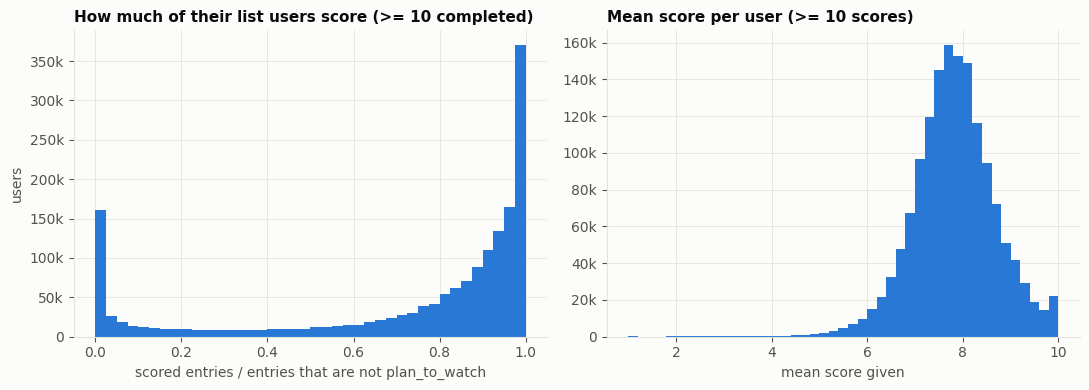

never score: 9.5% of users; score at least 90% of what they watched: 46.0% of users with >= 10 completed
mean of user means 7.82, 10th to 90th percentile 6.81 to 8.89


In [6]:
raters = users.filter(pl.col("n_scored") >= 10)
share_scored = (users.filter(pl.col("n_completed") >= 10)
                     .select((pl.col("n_scored") / (pl.col("n_completed") + pl.col("n_watching") + pl.col("n_dropped")
                                                    + pl.col("n_on_hold"))).clip(0, 1))).to_series()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(share_scored, bins=40, color=BLUE)
axes[0].set_xlabel("scored entries / entries that are not plan_to_watch"); axes[0].set_ylabel("users")
axes[0].set_title("How much of their list users score (>= 10 completed)")
plotting.thousands(axes[0])
axes[1].hist(raters["mean_score"], bins=45, color=BLUE)
axes[1].set_xlabel("mean score given"); axes[1].set_title("Mean score per user (>= 10 scores)")
plotting.thousands(axes[1])
plt.tight_layout()
plt.show()
print(f"never score: {(users['n_scored'] == 0).mean():.1%} of users; "
      f"score at least 90% of what they watched: {(share_scored >= 0.9).mean():.1%} of users with >= 10 completed")
print(f"mean of user means {raters['mean_score'].mean():.2f}, "
      f"10th to 90th percentile {raters['mean_score'].quantile(0.1):.2f} to {raters['mean_score'].quantile(0.9):.2f}")

Scoring is bimodal. 46% of users with at least 10 completed anime score nearly everything they
watch, a visible group scores nothing, and 9.5% of all users have never given a score. An
unscored entry therefore mostly reflects the user's habit, not an opinion. Users are also
generous: the average user's mean score is 7.8 and 80% of users average between 6.8 and 8.9,
so the same raw score means different things from different users.

## 6. Taste: genres by gender

Each user's watched anime are counted per genre and divided by the user's watched total, so
heavy and light users weigh the same. An anime with several genres counts for each.

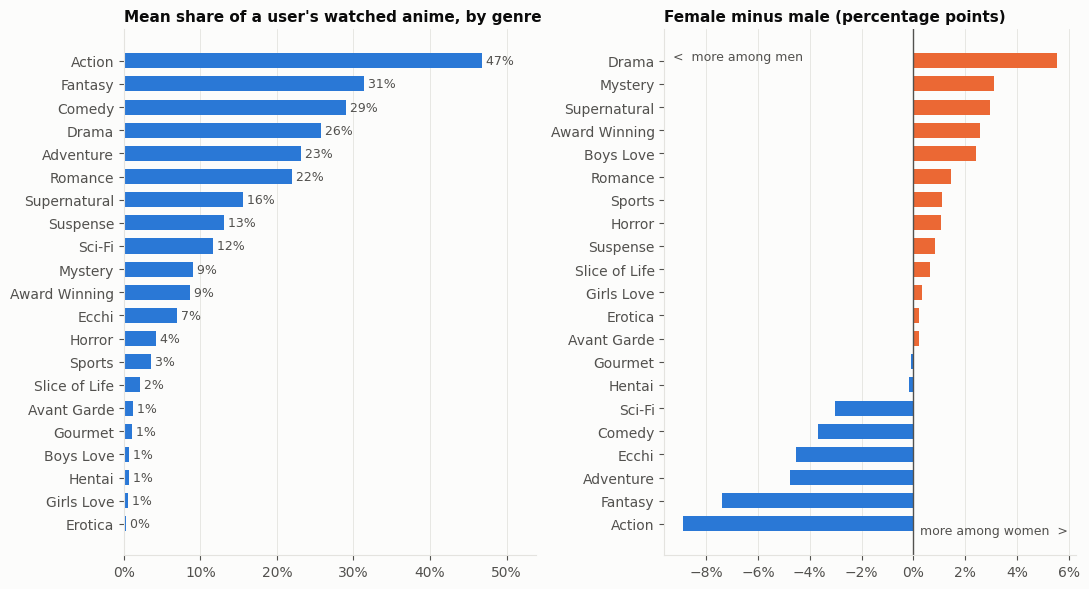

users with >= 20 watched: 1,638,670 (male 469,351, female 166,633)


In [7]:
genre_cols = [c for c in users.columns if c.startswith("genre_")]
active = users.filter(pl.col("n_watched") >= 20)
shares = active.select("gender", *[(pl.col(c) / pl.col("n_watched")).alias(c[6:]) for c in genre_cols])
overall = shares.drop("gender").mean().row(0, named=True)
by_gender = {g: shares.filter(pl.col("gender") == g).drop("gender").mean().row(0, named=True) for g in ("male", "female")}
order = sorted(overall, key=overall.get, reverse=True)
fig, axes = plt.subplots(1, 2, figsize=(11, 6))
bars = axes[0].barh(order, [overall[g] for g in order], color=BLUE, height=0.65)
axes[0].bar_label(bars, labels=[f" {overall[g]:.0%}" for g in order], color=MUTED, fontsize=9)
axes[0].invert_yaxis(); axes[0].grid(axis="y", visible=False); axes[0].set_xlim(0, max(overall.values()) * 1.15)
axes[0].xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
axes[0].set_title("Mean share of a user's watched anime, by genre")
diff = {g: by_gender["female"][g] - by_gender["male"][g] for g in order}
d_order = sorted(diff, key=diff.get)
axes[1].barh(d_order, [diff[g] for g in d_order], color=[ORANGE if diff[g] > 0 else BLUE for g in d_order], height=0.65)
axes[1].axvline(0, color=MUTED, lw=1)
axes[1].grid(axis="y", visible=False)
axes[1].xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
axes[1].set_title("Female minus male (percentage points)")
axes[1].text(0.98, 0.04, "more among women  >", transform=axes[1].transAxes, ha="right", color=MUTED, fontsize=9)
axes[1].text(0.02, 0.96, "<  more among men", transform=axes[1].transAxes, ha="left", va="top", color=MUTED, fontsize=9)
plt.tight_layout()
plt.show()
print(f"users with >= 20 watched: {active.height:,} (male {int((active['gender'] == 'male').sum()):,}, "
      f"female {int((active['gender'] == 'female').sum()):,})")

Action, Fantasy and Comedy lead for everyone. The gender gap is modest but consistent: women's
lists hold relatively more Drama, Mystery, Supernatural and Boys Love, men's more Action,
Fantasy, Adventure and Ecchi. The largest gaps are 6 to 9 percentage points, small next to the
overall shares, so gender is a weak prior that a user's history quickly overrides (and only
36% of users state it).